# 05 · dorothea: Kr energy resolution

**Purpose.** Reproduce the 2025 Kr results with the same cuts and fits, for fibers and for PMTs.

**Inputs.** `.dorothea.h5` kDSTs (`/DST/Events`) in `/data/marian/IC_ANALYSIS/dorothea/<fibers|pmts>/g<gain>/`: g365 = the 2025 runs (merged files), g1050 = the new runs (200 chunk files per detector). All files of the chosen sample and gain are read.

**Outputs.** Resolution numbers (printed) and plots.

**What is checked.** R < 30 mm cut, lifetime fit (ln of the mean S2e in 10 equal-count drift-time groups), lifetime correction, one-Gaussian fit. 2025 fibers result: 8.37% FWHM raw, 3.84% after correction, τ = 12.44 ± 0.45 ms (input 12 ms), 5165 events.

**Next step.** `06_qbb`. Run with `./submit.sh dorothea <fibers|pmts> <sample>`.

In [1]:
# Setup: run `source env.sh` before starting Jupyter, or pick the IC-3.8-2024-06-08 kernel.
import os, sys, glob
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
from icana import paths, checks, fits
print("ICDIR =", paths.ICDIR or "NOT SET (source env.sh)")

ICDIR = /scratch/marian/IC_ANALYSIS/external/IC/invisible_cities


### Choose the run
Files live in `/data/marian/IC_ANALYSIS/<city>/<det>/g<gain>/` (and `/scratch/marian/IC_ANALYSIS_OUT/`, same layout, before `tools/store.sh` copies them to `/data`). `paths.files(...)` finds the files you chose; if it does not exist it says so, and `paths.show()` lists what does.

In [2]:
# ---- Choose what to look at (change only this cell) ----
SAMPLE = '20250626_Next100_50Kev_ELoff_Kr'      # Kr 50Kev: gain 1050 fibers + PMTs; gain 365 fibers only (2025 result 3.84 %)
# SAMPLE = '20250624_Next100_1Kev_ELoff_Kr'     # Kr 1Kev: gain 365 only, fibers + PMTs (2025 comparison)

GAIN = 1050    # EL gain of the run: 1050 = new runs, 365 = 2025 runs

In [3]:
paths.show(SAMPLE)    # what exists for this sample: number of files per city, detector (fibers/pmts) and gain

det                                      fibers      pmts
gain                                       1050 365  1050
sample                          city                     
20250626_Next100_50Kev_ELoff_Kr detsim      200   40  200
                                dorothea    200    1  200
                                hypathia    200   40  200

In [4]:
def load_dst(det, gain=None, sample=None):
    """All kDST rows of one run (every dorothea file of that sample, detector and gain)."""
    fs = paths.files("dorothea", det, gain or GAIN, sample or SAMPLE)
    return pd.concat([pd.read_hdf(f, "/DST/Events") for f in fs], ignore_index=True), fs

RCUT = 30          # mm
V_DRIFT = 1.0      # mm/us (detsim drift_velocity)

# Fit ranges. Gain 365 (2025 runs): the 2025 bins. Other gains: the same relative range placed around the median
# of the peak: raw 0.744-1.202 x median (50 bins), corrected 0.712-1.172 x median (100 bins),
# i.e. 6.5e3-1.05e4 and 6.5e3-1.07e4 pes divided by the 2025 means.
BINS_2025 = dict(bins_raw=np.linspace(6.5e3, 1.05e4, 50), bins_cor=np.linspace(6.5e3, 1.07e4, 100))
REL_RAW, REL_COR = (6.5e3 / 8734, 1.05e4 / 8734), (6.5e3 / 9128, 1.07e4 / 9128)

def kr_resolution(dst, label, gain, weighted=False):
    bins_raw, bins_cor = (BINS_2025["bins_raw"], BINS_2025["bins_cor"]) if gain == 365 else (None, None)
    d  = dst[dst.R < RCUT]
    dt = d.Z.values / V_DRIFT
    if bins_raw is None: m = np.median(d.S2e.values); bins_raw = np.linspace(REL_RAW[0] * m, REL_RAW[1] * m, 50)
    raw = fits.fit_peak(d.S2e.values, bins_raw, weighted)
    lt  = fits.fit_lifetime(dt, d.S2e.values, n=10, weighted=weighted)
    e_cor = d.S2e.values * np.exp(dt / lt["tau_us"])
    if bins_cor is None: m = np.median(e_cor); bins_cor = np.linspace(REL_COR[0] * m, REL_COR[1] * m, 100)
    cor = fits.fit_peak(e_cor, bins_cor, weighted)
    print(f"{label} [{'weighted fits' if weighted else '2025 method'}]: {len(d)} events with R < {RCUT} mm")
    print(f"   raw       : mu {raw['mu']:.0f} pes, FWHM {raw['fwhm_pct']:.2f} ± {raw['fwhm_pct_err']:.2f} %")
    print(f"   lifetime  : {lt['tau_us']/1e3:.2f} ± {lt['tau_err_us']/1e3:.2f} ms (input 12 ms)")
    print(f"   corrected : mu {cor['mu']:.0f} pes, FWHM {cor['fwhm_pct']:.2f} ± {cor['fwhm_pct_err']:.2f} %")
    return dict(raw=raw, lt=lt, cor=cor, d=d)

from icana import plots
plots.set_style()
SAVE = False         # True: also save each figure to work/figures/ (PDF for the thesis, PNG)
def show(fig, name):
    if SAVE: print("saved", plots.save(fig, name))
    plt.show()

## 2025 fibers result (50Kev sample, gain 365)
Fixed reference, does not depend on the cell above.

In [5]:
dst50, fs = load_dst("fibers", 365, "20250626_Next100_50Kev_ELoff_Kr"); print(fs)
r50  = kr_resolution(dst50, "fibers, 50Kev, gain 365", 365)                  # same method as the 2025 notebook
r50w = kr_resolution(dst50, "fibers, 50Kev, gain 365", 365, weighted=True)   # Poisson-weighted fits, for comparison

['/data/marian/IC_ANALYSIS/dorothea/fibers/g365/20250626_Next100_50Kev_ELoff_Kr_0-40.dorothea.h5']
fibers, 50Kev, gain 365 [2025 method]: 5165 events with R < 30 mm
   raw       : mu 8734 pes, FWHM 8.37 ± 0.17 %
   lifetime  : 12.44 ± 0.45 ms (input 12 ms)
   corrected : mu 9128 pes, FWHM 3.84 ± 0.02 %
fibers, 50Kev, gain 365 [weighted fits]: 5165 events with R < 30 mm
   raw       : mu 8727 pes, FWHM 7.18 ± 0.14 %
   lifetime  : 11.86 ± 0.17 ms (input 12 ms)
   corrected : mu 9148 pes, FWHM 3.80 ± 0.02 %


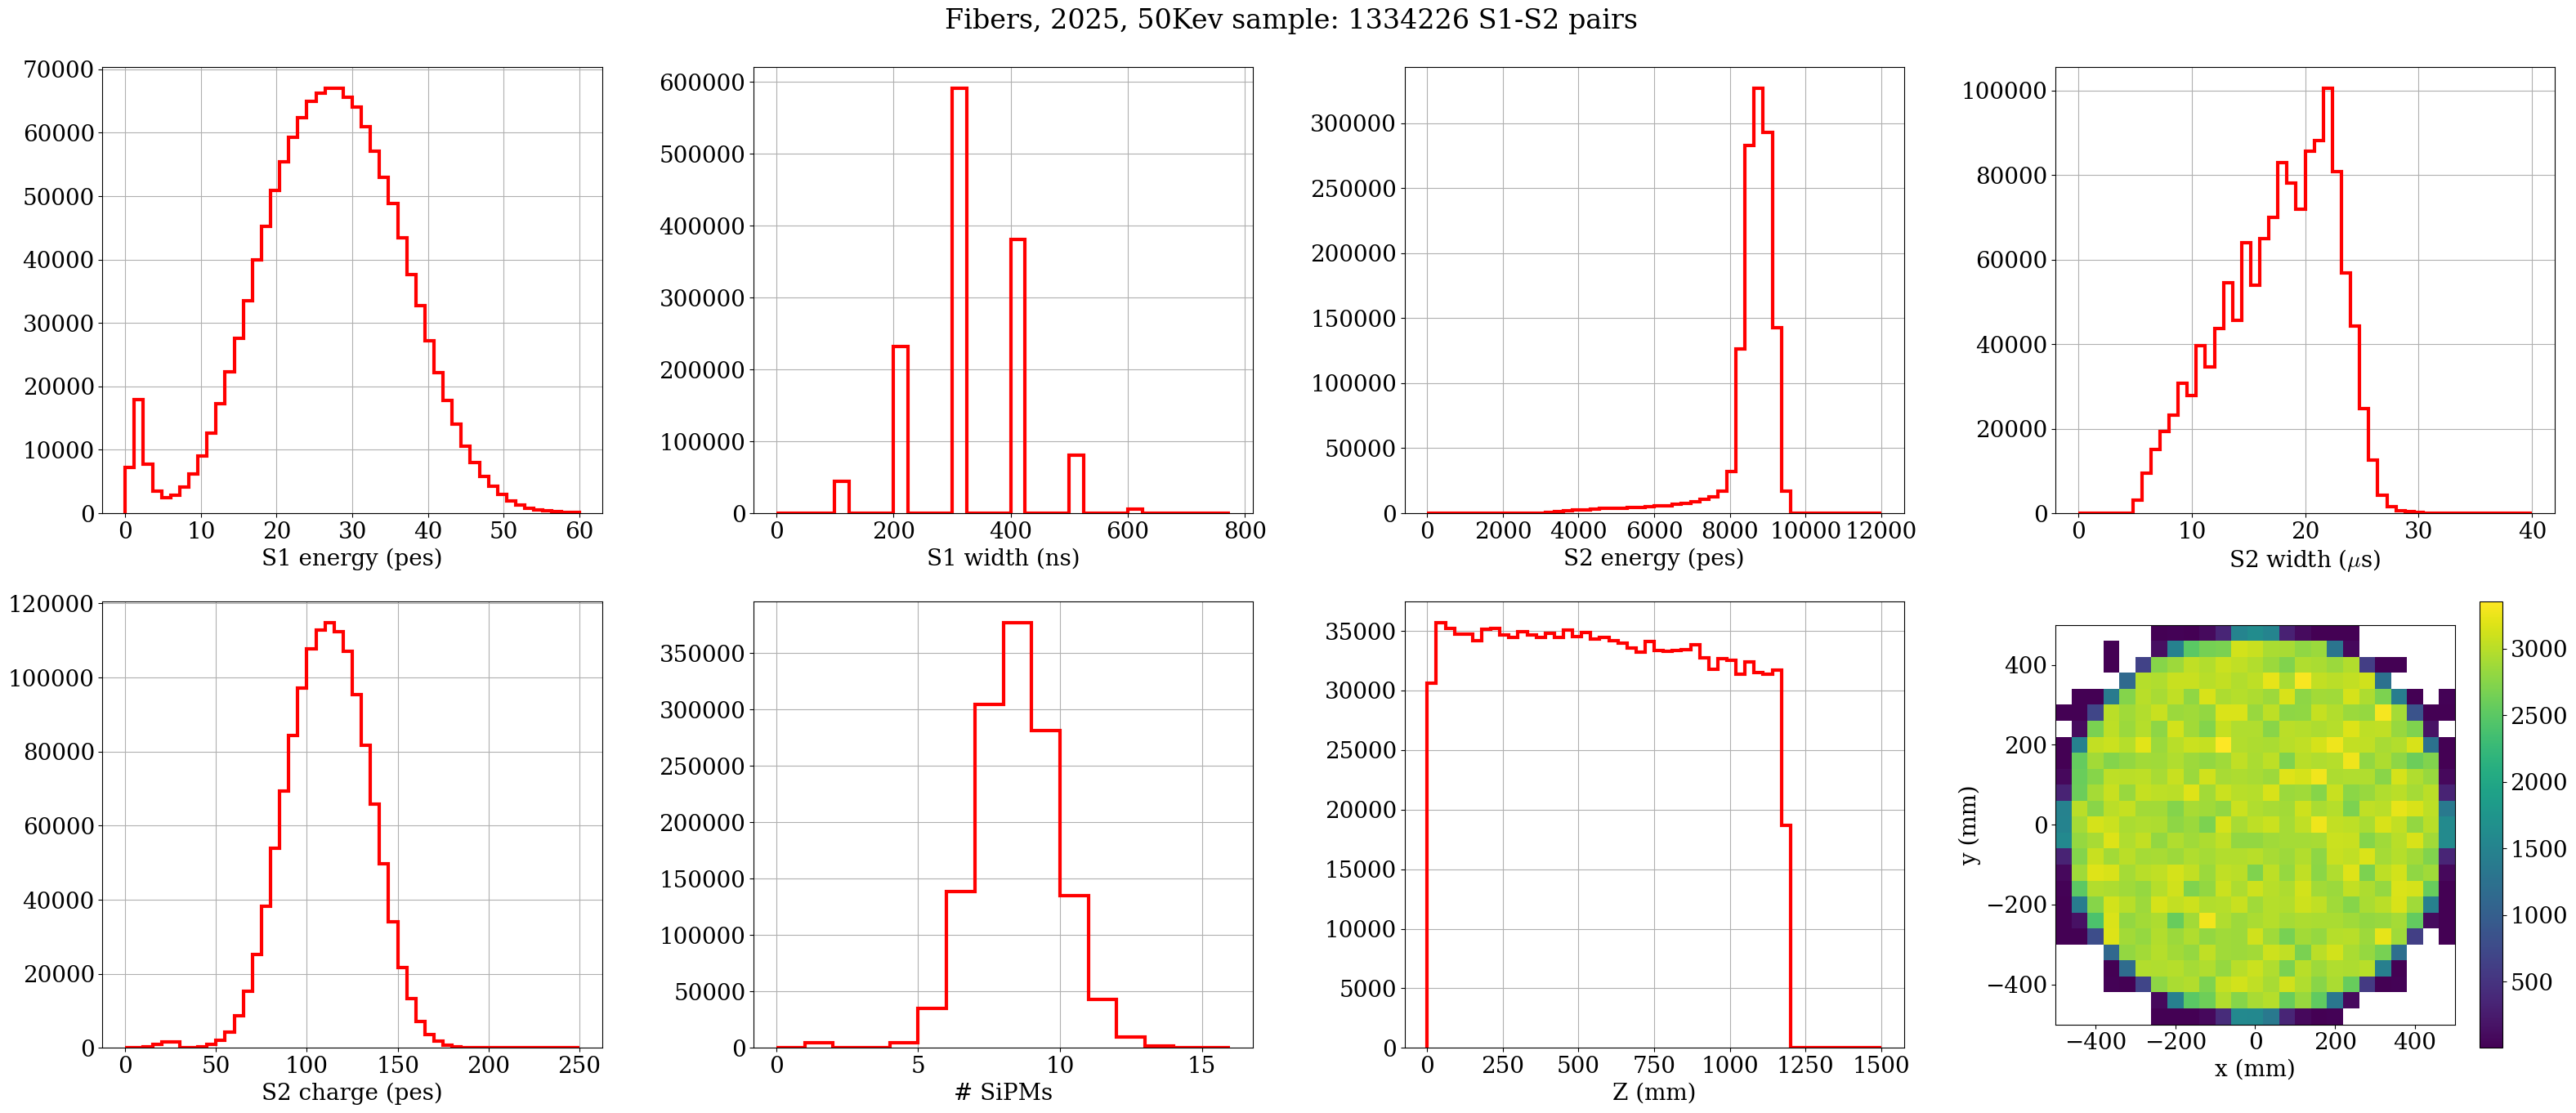

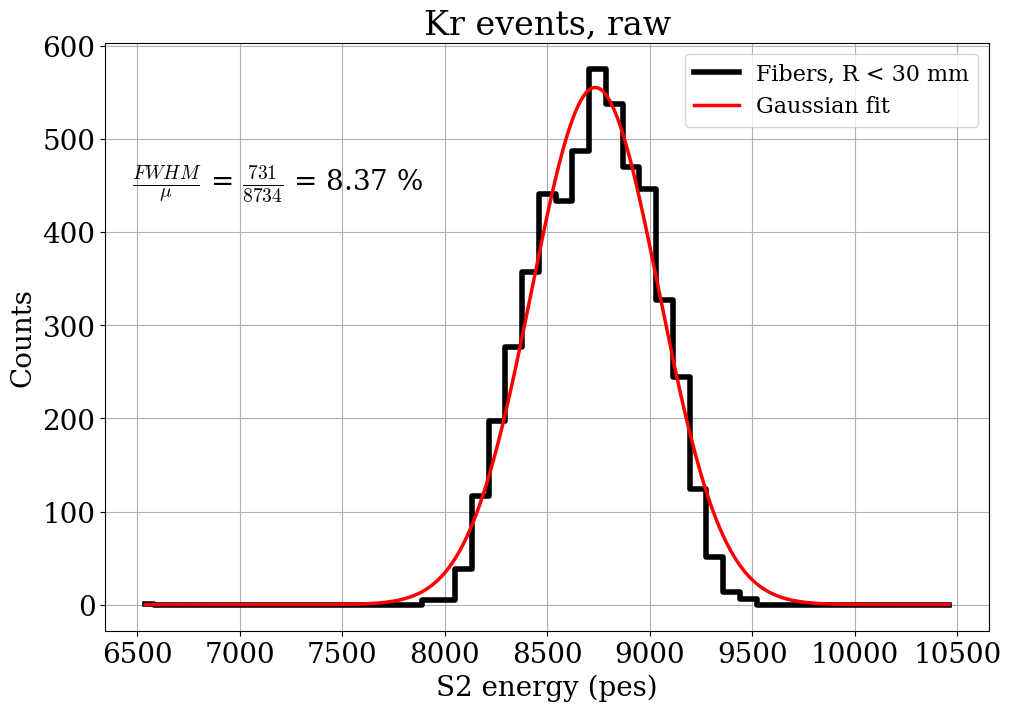

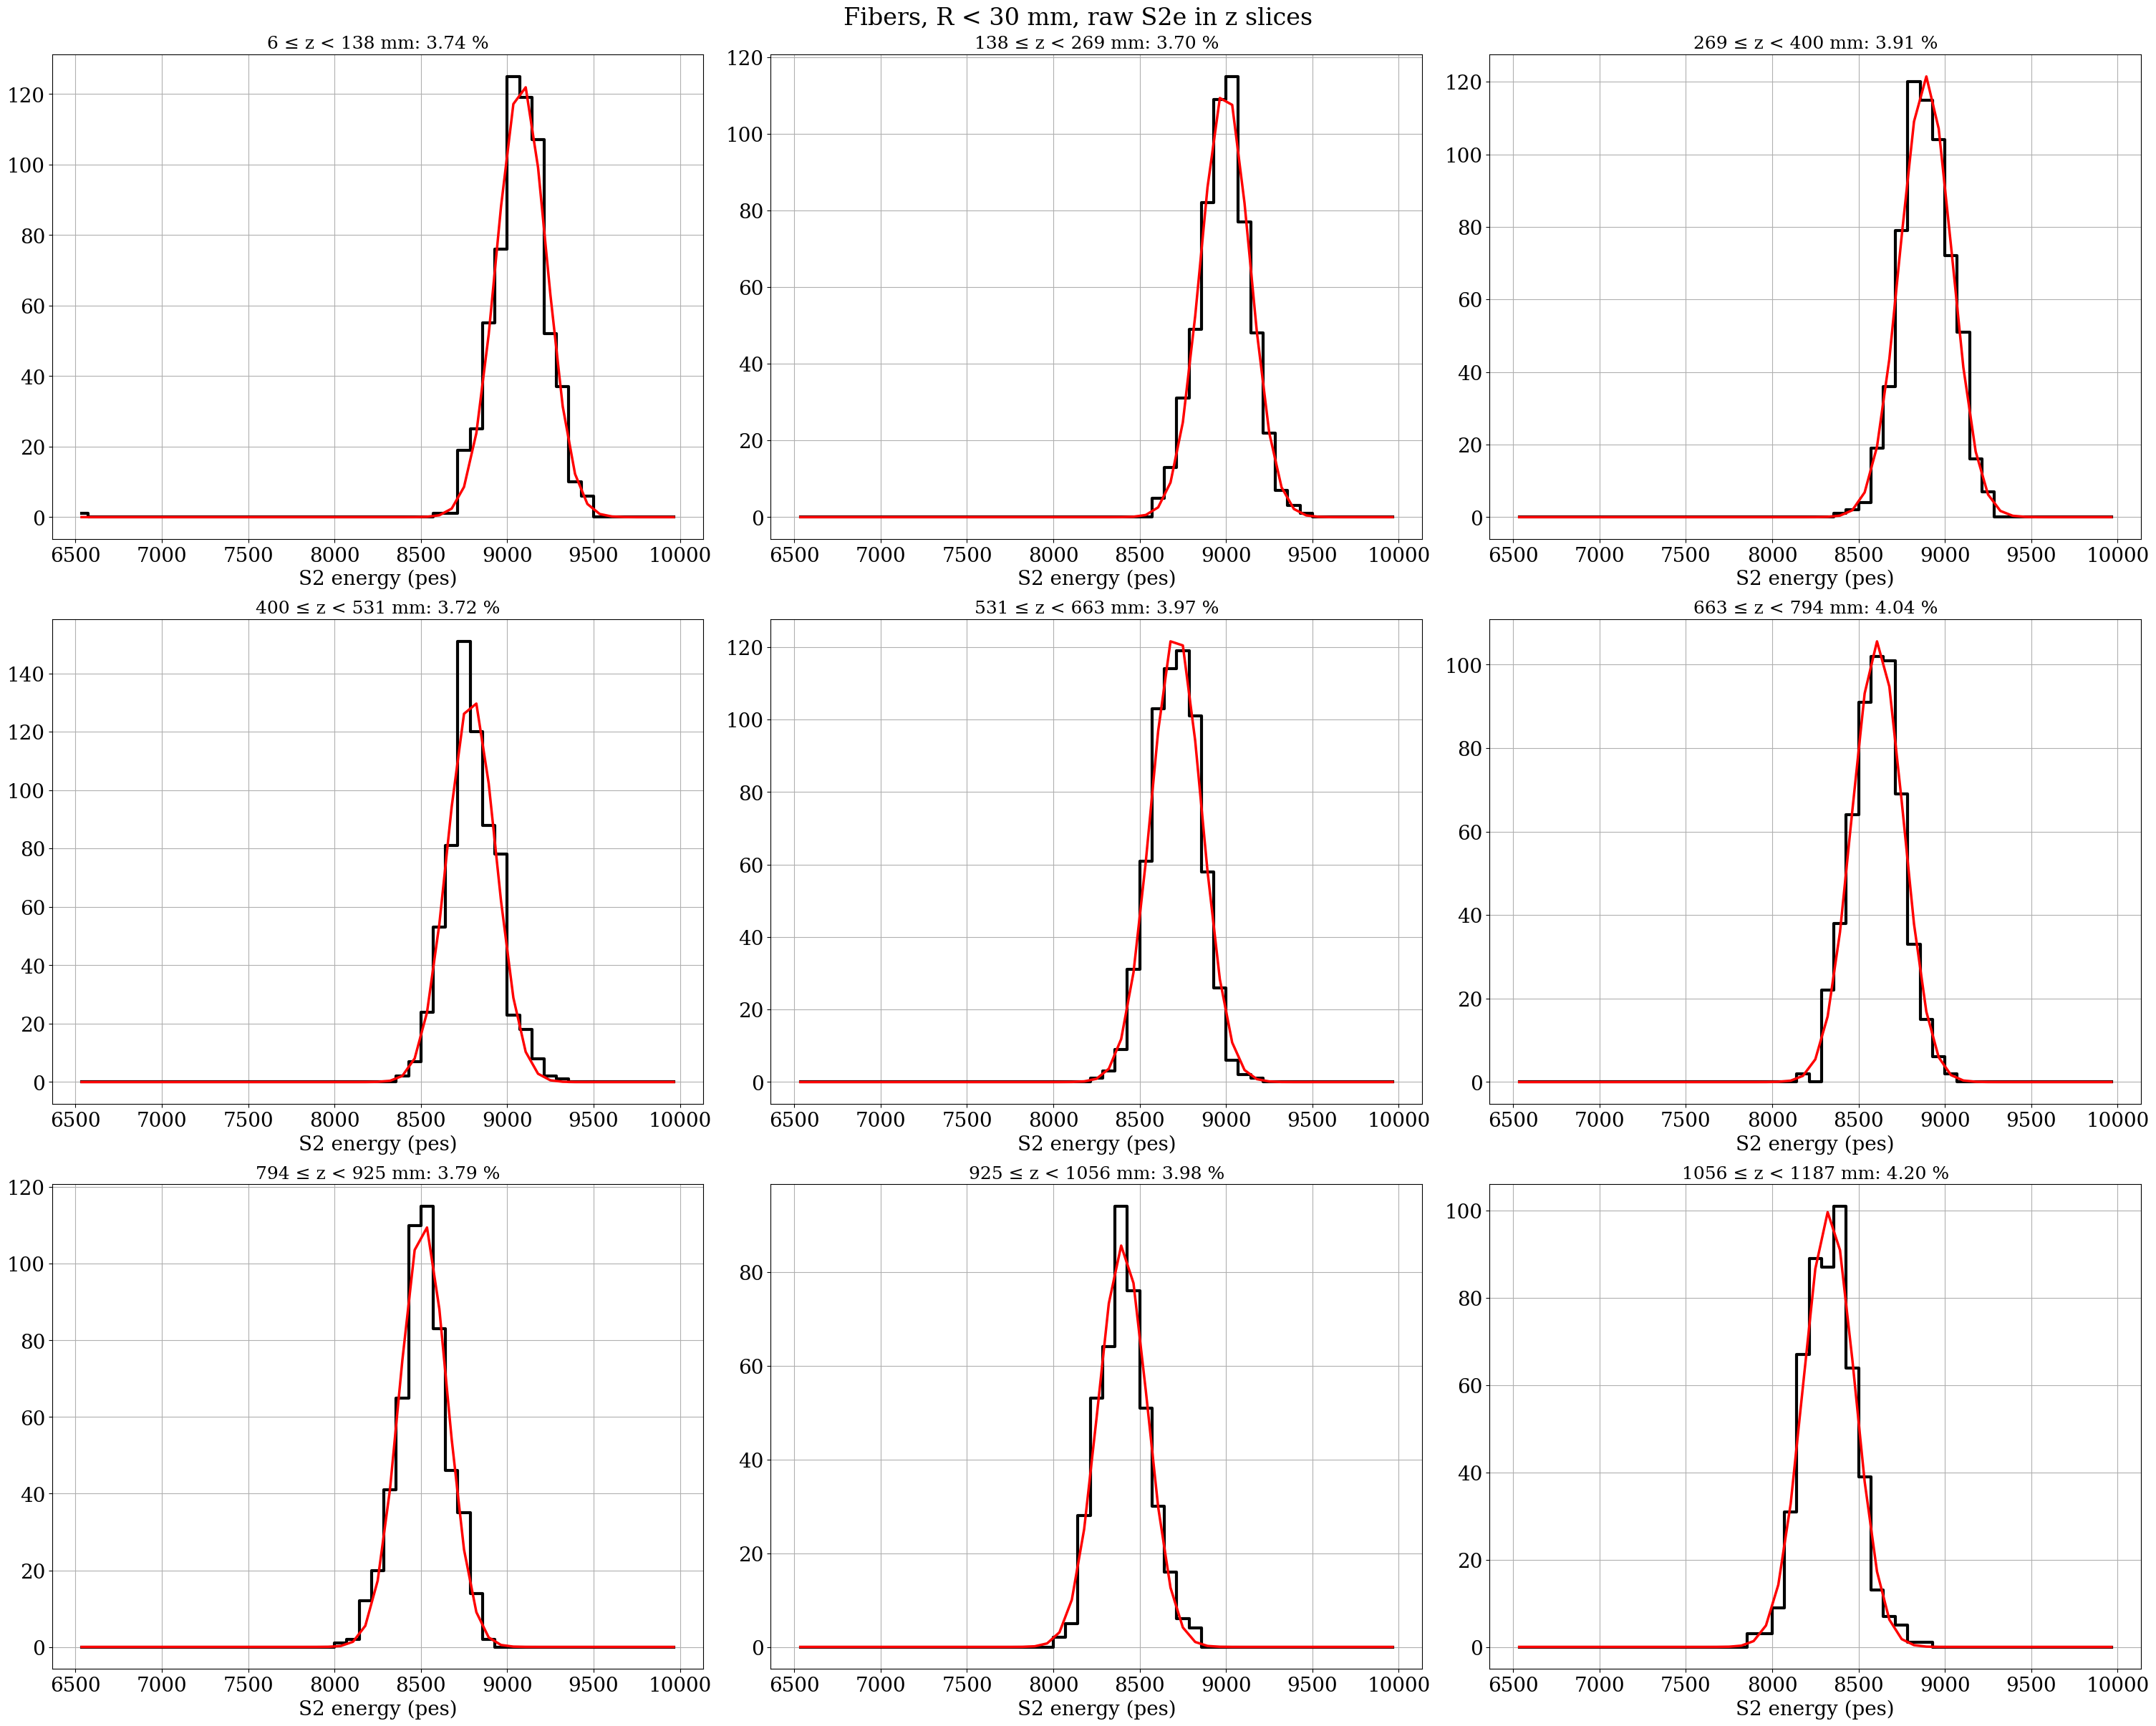

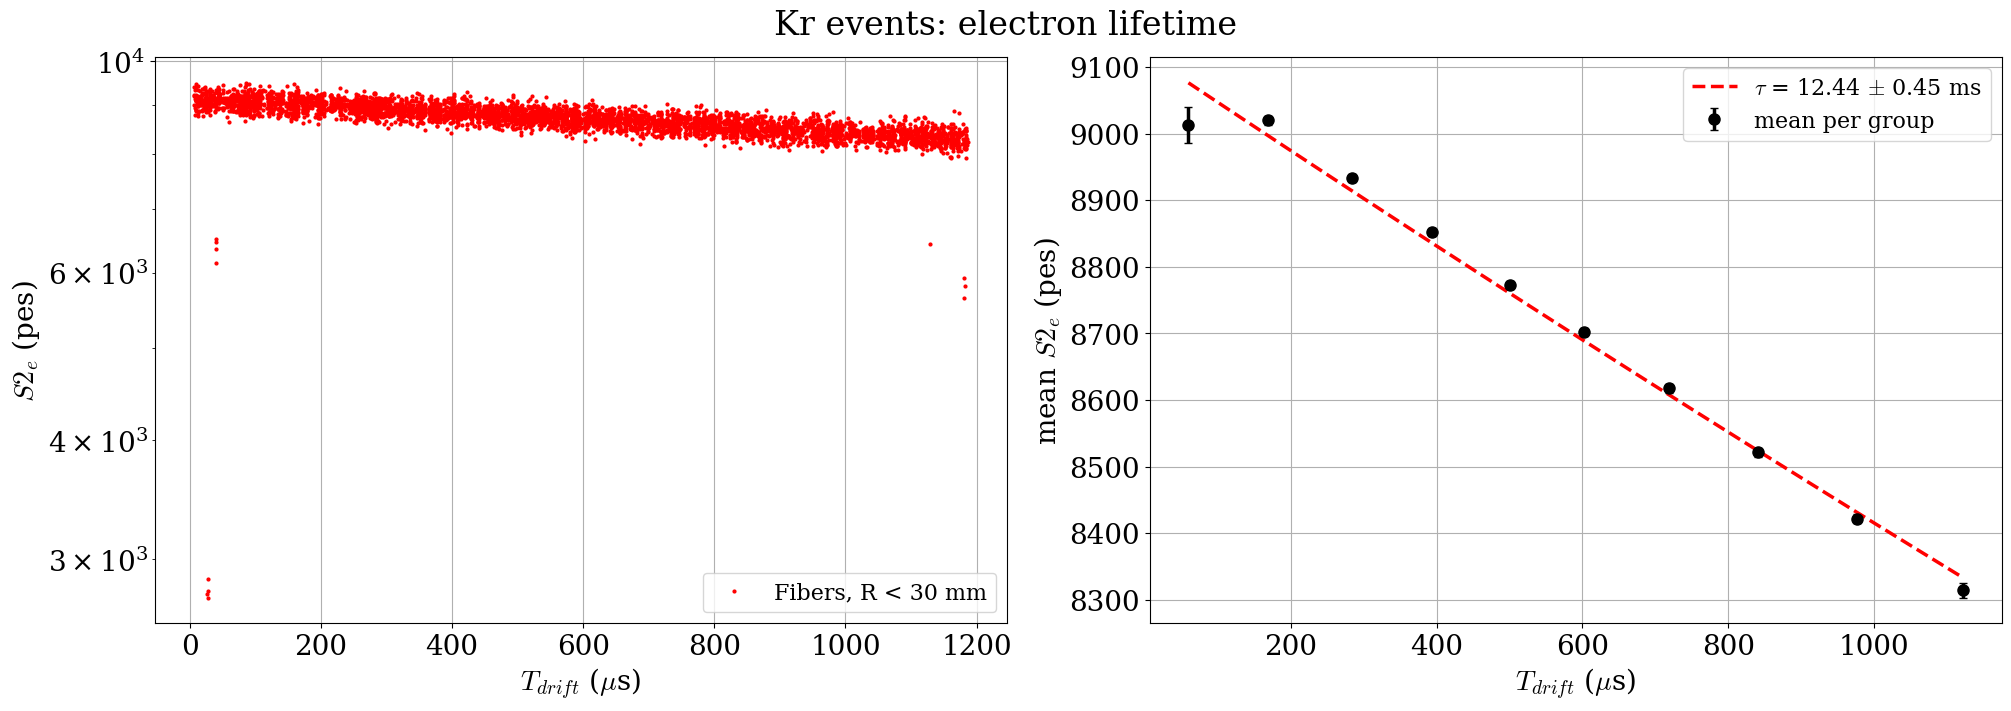

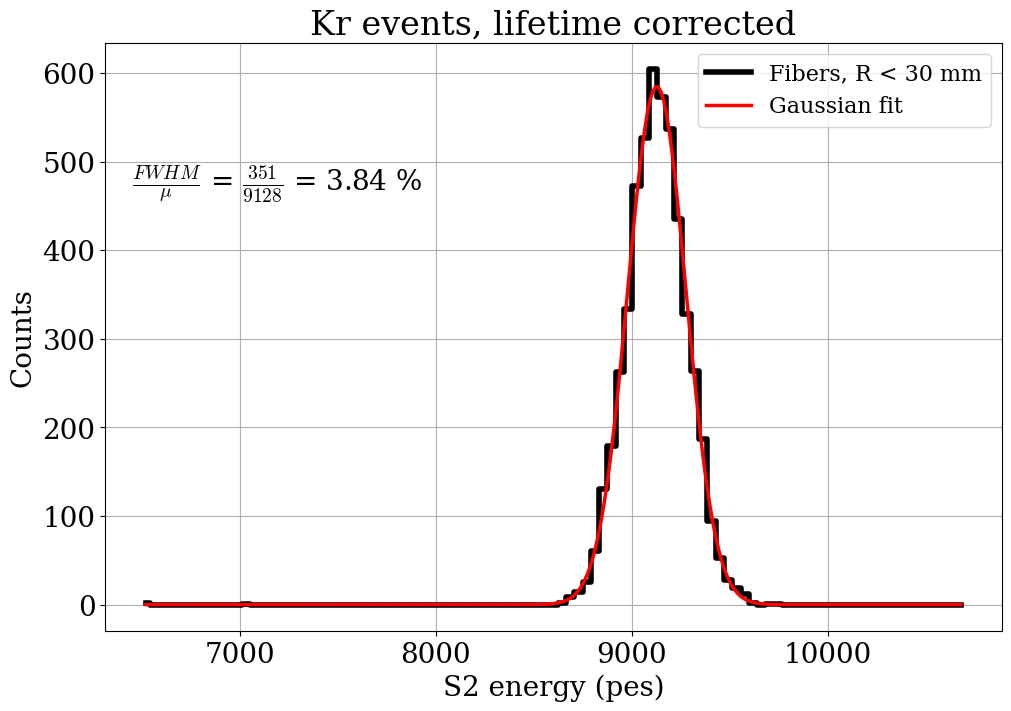

In [6]:
# Plots (2025 style), see the next cell for what each one shows
d50 = r50["d"]; dt50 = d50.Z.values / V_DRIFT
show(plots.dst_overview(dst50, "Fibers, 2025, 50Kev sample"), "kr50_fibers_2025_overview")
show(plots.peak_fit(r50["raw"], f"Fibers, R < {RCUT} mm", "Kr events, raw"), "kr50_fibers_2025_peak_raw")
show(plots.peak_in_z_slices(dst50, RCUT, np.linspace(6.5e3, 1.0e4, 50)), "kr50_fibers_2025_peak_zslices")
show(plots.lifetime(dt50, d50.S2e.values, r50["lt"], f"Fibers, R < {RCUT} mm"), "kr50_fibers_2025_lifetime")
show(plots.peak_fit(r50["cor"], f"Fibers, R < {RCUT} mm", "Kr events, lifetime corrected"), "kr50_fibers_2025_peak_corrected")

**What the plots show** (same as `python_cluster/notebooks/20250614_s2simulation_ICdorothea.ipynb`):
1. **Overview** of the kDST (one row per S1-S2 pair): S1 and S2 energy and width, S2 charge on the SiPMs, number of SiPMs, Z, and the x-y map. All events, before cuts.
2. **Raw Kr peak**: S2 energy for R < 30 mm with a Gaussian fit, no correction. Broad, because electrons are lost while drifting.
3. **The same in 9 z slices**: each slice is narrower, and the peak moves down with z: that is the lifetime.
4. **Lifetime**: S2e vs drift time (left); the means in 10 equal-count groups and the exponential fit (right), τ to compare with the 12 ms put into detsim.
5. **Corrected Kr peak**: S2e × exp(t/τ). This FWHM is the result (2025: 3.84 %).

`SAVE = True` writes them to `work/figures/` (names start with `kr50_fibers_2025_`).

## Fibers vs PMTs on the same nexus events (1Kev sample, gain 365)
Fixed reference, does not depend on the cell above.
Same cuts and fits. Expected from photostatistics + Fano (Claude's estimate with el_gain 365, not a result): about 3.3% fibers, 3.9% PMTs.

With R < 30 mm the 1Kev sample has only ~150 events per detector, too few for a precise comparison. The full comparison, on the 50Kev sample at gain 1050, is in the last section.

In [7]:
res = {}
for det in ["fibers", "pmts"]:
    dst, fs = load_dst(det, 365, "20250624_Next100_1Kev_ELoff_Kr"); print(fs)
    res[det] = kr_resolution(dst, f"{det}, 1Kev, gain 365", 365)
    res[det]["dst"] = dst
print(f"S2 ratio fibers/PMTs (corrected peak): {res['fibers']['cor']['mu']/res['pmts']['cor']['mu']:.3f}")

['/data/marian/IC_ANALYSIS/dorothea/fibers/g365/20250624_Next100_1Kev_ELoff_Kr_ALL.dorothea.h5']
fibers, 1Kev, gain 365 [2025 method]: 151 events with R < 30 mm
   raw       : mu 8790 pes, FWHM 6.79 ± 0.38 %
   lifetime  : 12.56 ± 0.42 ms (input 12 ms)
   corrected : mu 9132 pes, FWHM 3.44 ± 0.12 %
['/data/marian/IC_ANALYSIS/dorothea/pmts/g365/20250624_Next100_1Kev_ELoff_Kr_ALL.dorothea.h5']
pmts, 1Kev, gain 365 [2025 method]: 157 events with R < 30 mm
   raw       : mu 5608 pes, FWHM 7.03 ± inf %
   lifetime  : 12.68 ± 1.06 ms (input 12 ms)
   corrected : mu 5834 pes, FWHM 4.66 ± inf %
S2 ratio fibers/PMTs (corrected peak): 1.565


### Fibers vs PMTs, plots (2025 style)
The same overview with both detectors on top of each other (PMTs black, fibers red), and the ratio of the mean S1 and S2 energies. The last panel is S1 vs S2 per event.
Then the corrected Kr peak of each detector. Uses `res` from the cell above (1Kev sample, gain 365).

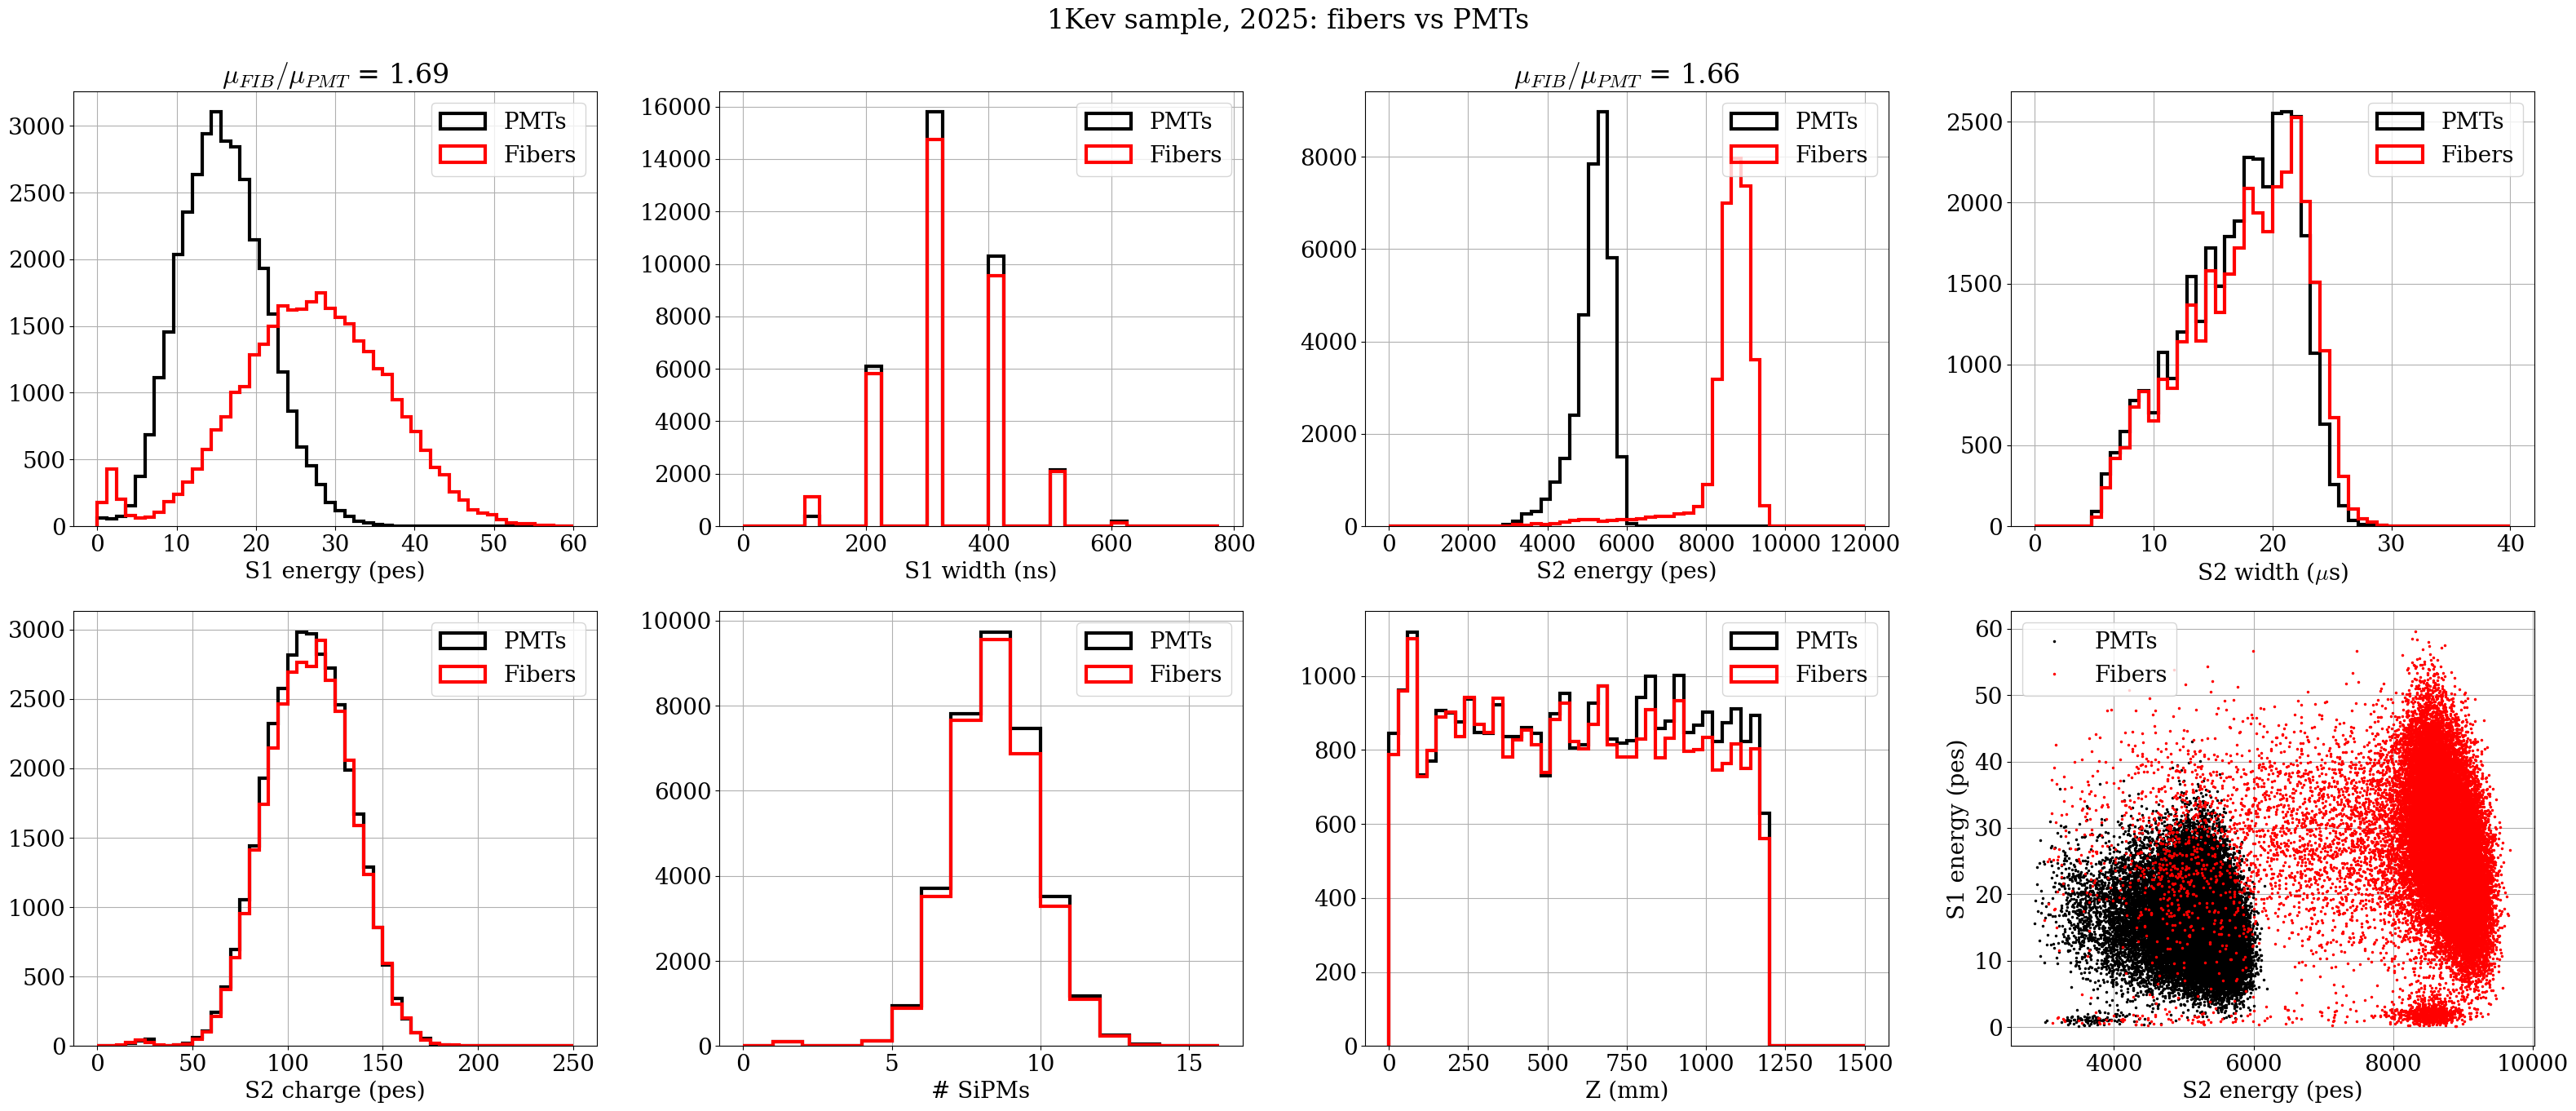

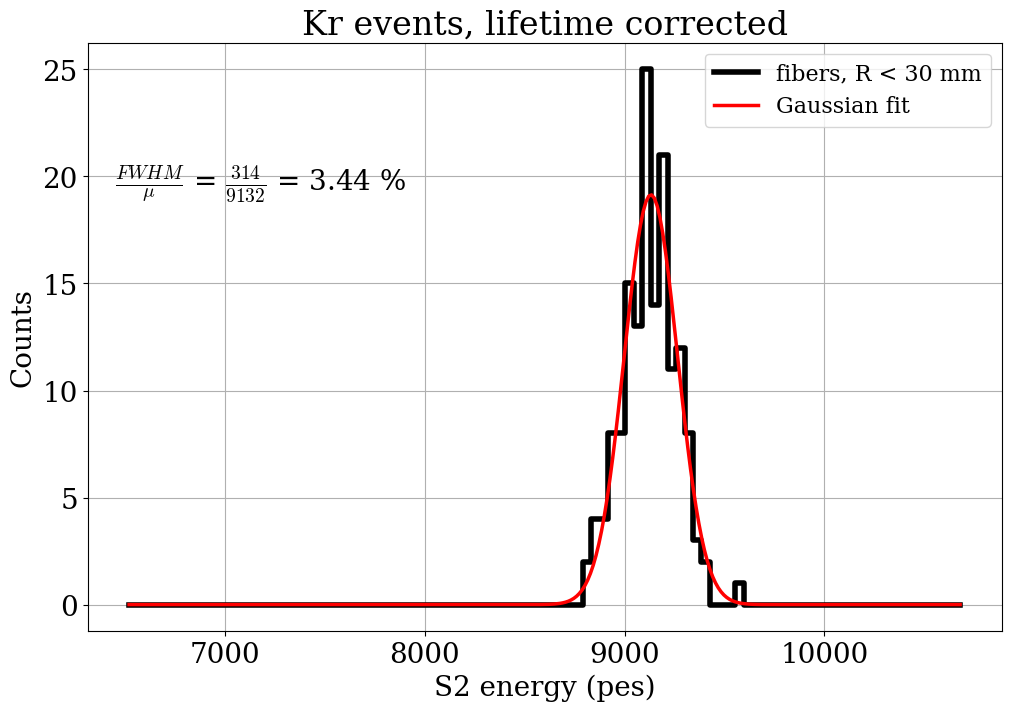

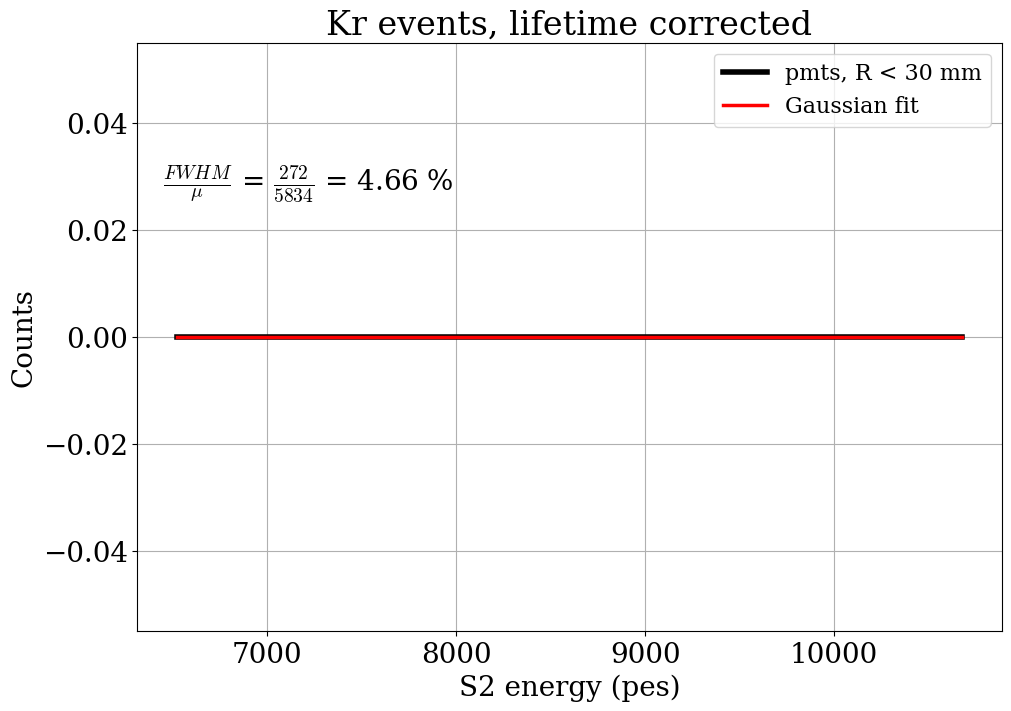

In [8]:
show(plots.dst_compare(res["fibers"]["dst"], res["pmts"]["dst"], "1Kev sample, 2025: fibers vs PMTs"), "kr1_2025_fib_vs_pmt")
for det in ["fibers", "pmts"]:
    show(plots.peak_fit(res[det]["cor"], f"{det}, R < {RCUT} mm", "Kr events, lifetime corrected"), f"kr1_{det}_2025_peak_corrected")

## Your choice (`SAMPLE`, `GAIN` from the top cell): fibers vs PMTs
With the default choice (50Kev, gain 1050):
The new runs (EL gain 1050, diffusion 1.072 / 0.267 mm/√cm, lifetime 12 ms), 200 chunk files per detector, the same 2 million nexus events for both. Same cuts and fits as above; the fit ranges are placed around each peak (see `REL_RAW`, `REL_COR`).

First numbers (2026-11-22, same code as a script): fibers 3.07 % FWHM (5203 events, τ = 12.23 ms), PMTs 3.46 % (5423 events, τ = 12.84 ms), fibers/PMTs corrected S2 = 1.56. The ± on the FWHM is the fit error only.

Not only the gain changed with respect to 2025: the diffusion did too, so 3.84 % → 3.07 % for fibers is not a pure gain effect.

In [9]:
new = {}
for det in ["fibers", "pmts"]:
    dst, fs = load_dst(det)
    print(f"{det}: {len(fs)} files in {os.path.dirname(fs[0])}")
    new[det]       = kr_resolution(dst, f"{det}, {SAMPLE}, gain {GAIN}", GAIN)
    new[det + "w"] = kr_resolution(dst, f"{det}, {SAMPLE}, gain {GAIN}", GAIN, weighted=True)
    new[det]["dst"] = dst
print(f"S2 ratio fibers/PMTs (corrected peak): {new['fibers']['cor']['mu'] / new['pmts']['cor']['mu']:.3f}")
print(f"Gain check, fibers: corrected peak {new['fibers']['cor']['mu'] / r50['cor']['mu']:.3f} x the 2025 one ({GAIN}/365 = {GAIN/365:.3f})")

pd.DataFrame({
    "2025 fibers (g365)": [r50["d"].shape[0], r50["raw"]["fwhm_pct"], r50["lt"]["tau_us"] / 1e3, r50["cor"]["mu"], r50["cor"]["fwhm_pct"], r50w["cor"]["fwhm_pct"]],
    f"fibers (g{GAIN})": [new["fibers"]["d"].shape[0], new["fibers"]["raw"]["fwhm_pct"], new["fibers"]["lt"]["tau_us"] / 1e3, new["fibers"]["cor"]["mu"], new["fibers"]["cor"]["fwhm_pct"], new["fibersw"]["cor"]["fwhm_pct"]],
    f"PMTs (g{GAIN})":   [new["pmts"]["d"].shape[0],   new["pmts"]["raw"]["fwhm_pct"],   new["pmts"]["lt"]["tau_us"] / 1e3,   new["pmts"]["cor"]["mu"],   new["pmts"]["cor"]["fwhm_pct"],   new["pmtsw"]["cor"]["fwhm_pct"]],
}, index=["events R < 30 mm", "raw FWHM (%)", "lifetime (ms)", "corrected peak (pes)", "corrected FWHM (%)", "corrected FWHM, weighted (%)"]).round(2)

fibers: 200 files in /data/marian/IC_ANALYSIS/dorothea/fibers/g1050
fibers, 20250626_Next100_50Kev_ELoff_Kr, gain 1050 [2025 method]: 5203 events with R < 30 mm
   raw       : mu 25110 pes, FWHM 8.24 ± 0.23 %
   lifetime  : 12.23 ± 0.18 ms (input 12 ms)
   corrected : mu 26271 pes, FWHM 3.07 ± 0.01 %
fibers, 20250626_Next100_50Kev_ELoff_Kr, gain 1050 [weighted fits]: 5203 events with R < 30 mm
   raw       : mu 25056 pes, FWHM 6.80 ± 0.15 %
   lifetime  : 11.99 ± 0.09 ms (input 12 ms)
   corrected : mu 26295 pes, FWHM 3.06 ± 0.02 %
pmts: 200 files in /data/marian/IC_ANALYSIS/dorothea/pmts/g1050
pmts, 20250626_Next100_50Kev_ELoff_Kr, gain 1050 [2025 method]: 5423 events with R < 30 mm
   raw       : mu 16071 pes, FWHM 8.16 ± 0.16 %
   lifetime  : 12.84 ± 0.48 ms (input 12 ms)
   corrected : mu 16793 pes, FWHM 3.46 ± 0.02 %
pmts, 20250626_Next100_50Kev_ELoff_Kr, gain 1050 [weighted fits]: 5423 events with R < 30 mm
   raw       : mu 16059 pes, FWHM 6.97 ± 0.13 %
   lifetime  : 12.32 ± 0.

,2025 fibers (g365),fibers (g1050),PMTs (g1050)
events R < 30 mm,5165.00,5203.00,5423.00
raw FWHM (%),8.37,8.24,8.16
lifetime (ms),12.44,12.23,12.84
corrected peak (pes),9127.63,26270.52,16792.81
corrected FWHM (%),3.84,3.07,3.46
"corrected FWHM, weighted (%)",3.80,3.06,3.45


### Your choice, plots
Overview of both kDSTs on top of each other (S2 axes stretched by GAIN/365), then for each detector the lifetime fit and the corrected Kr peak. Names start with `kr_<sample>_g<GAIN>_`.

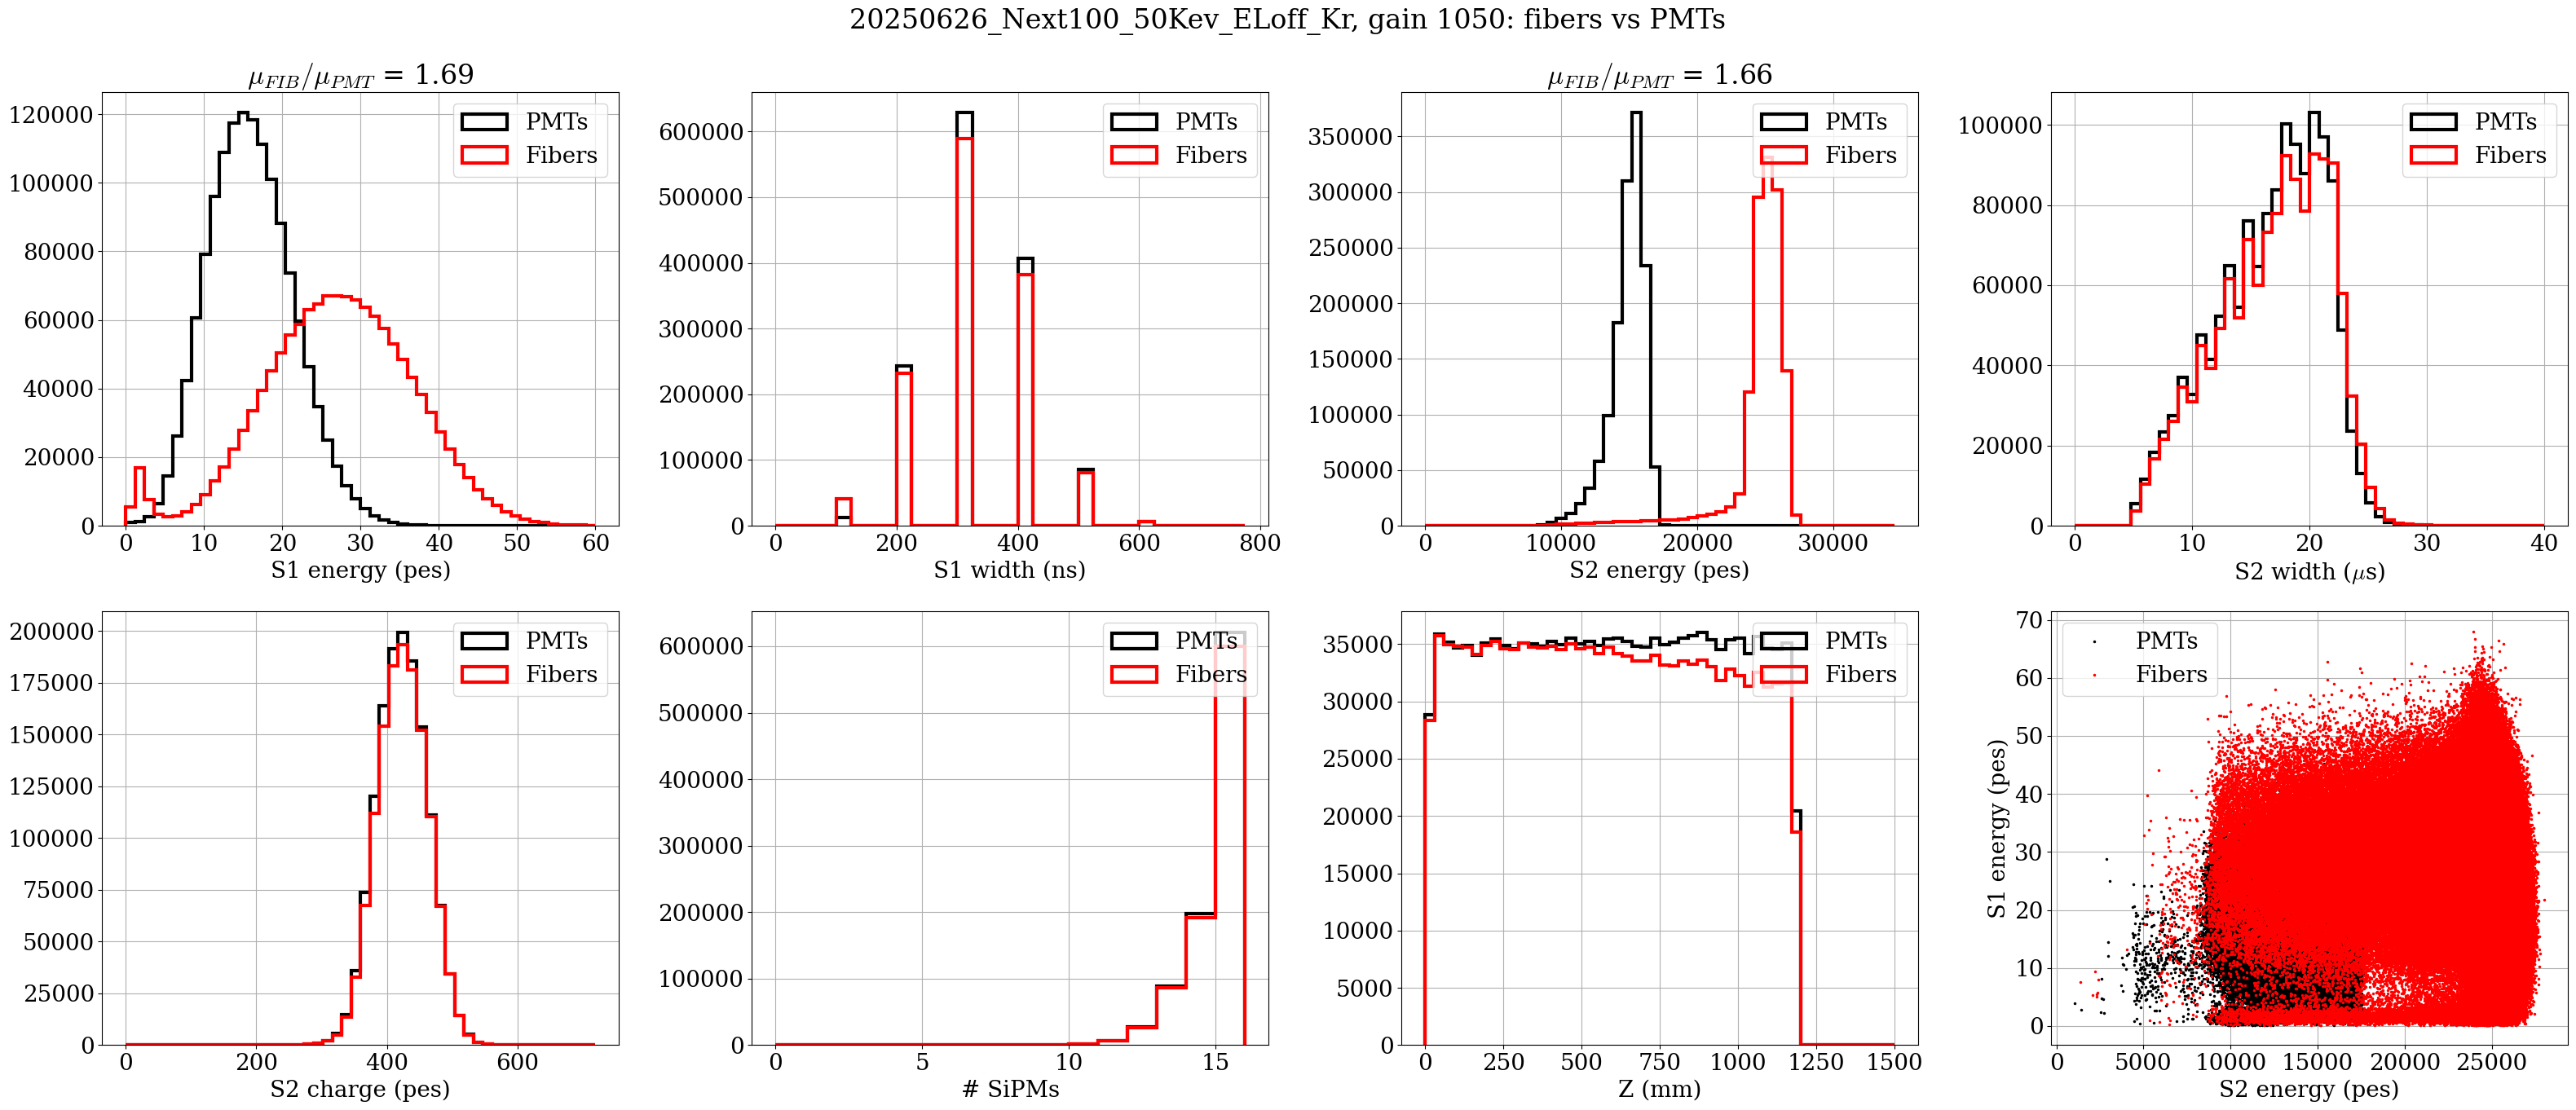

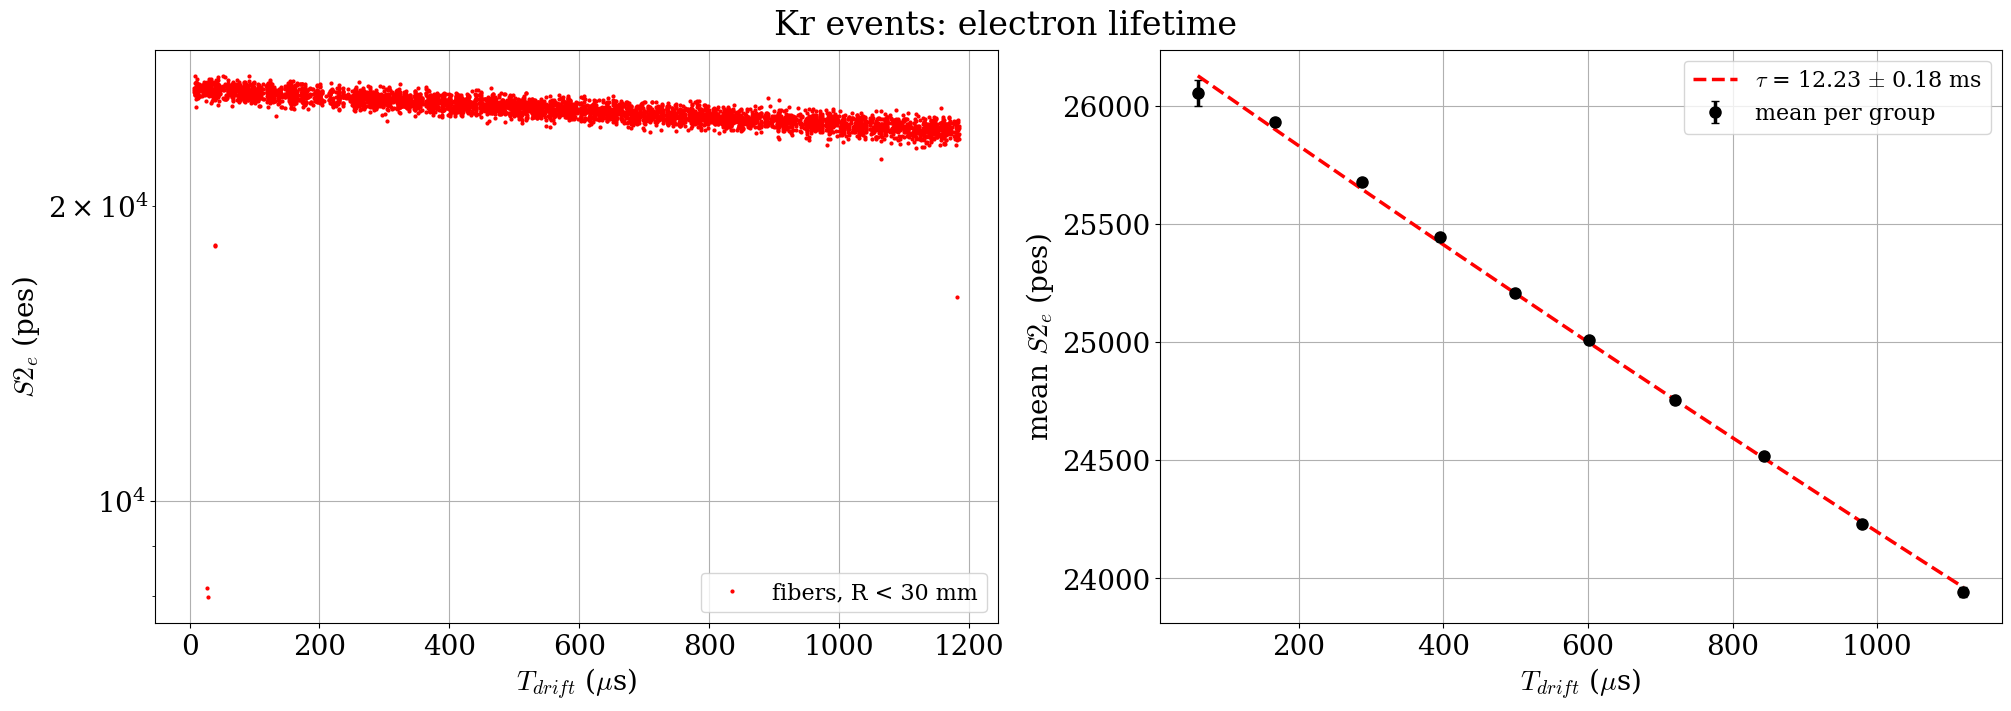

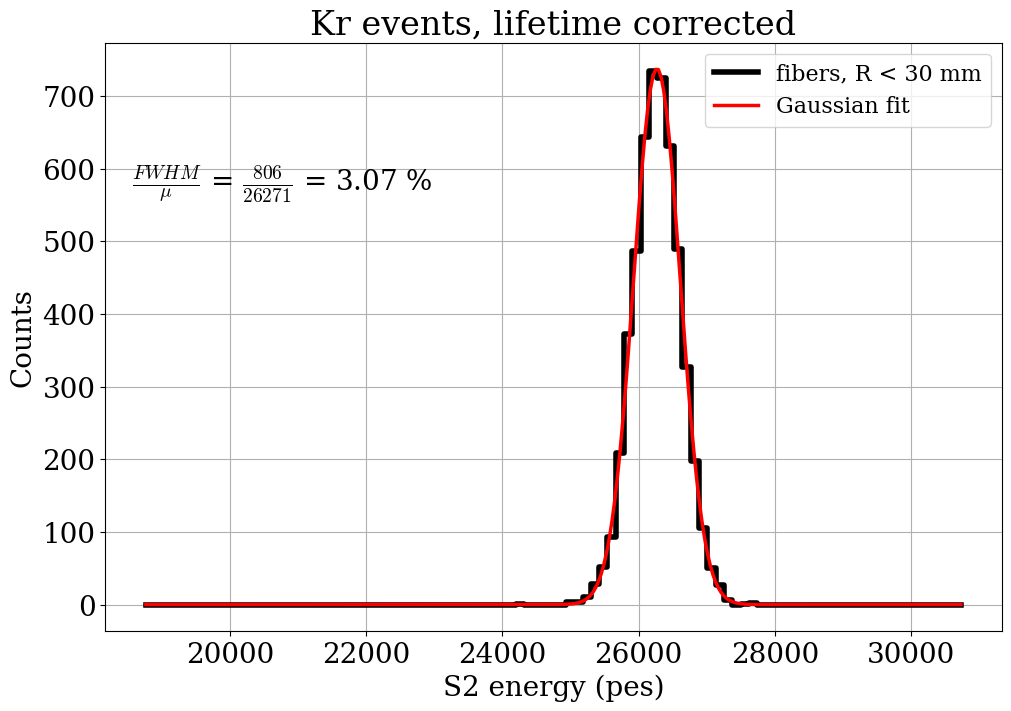

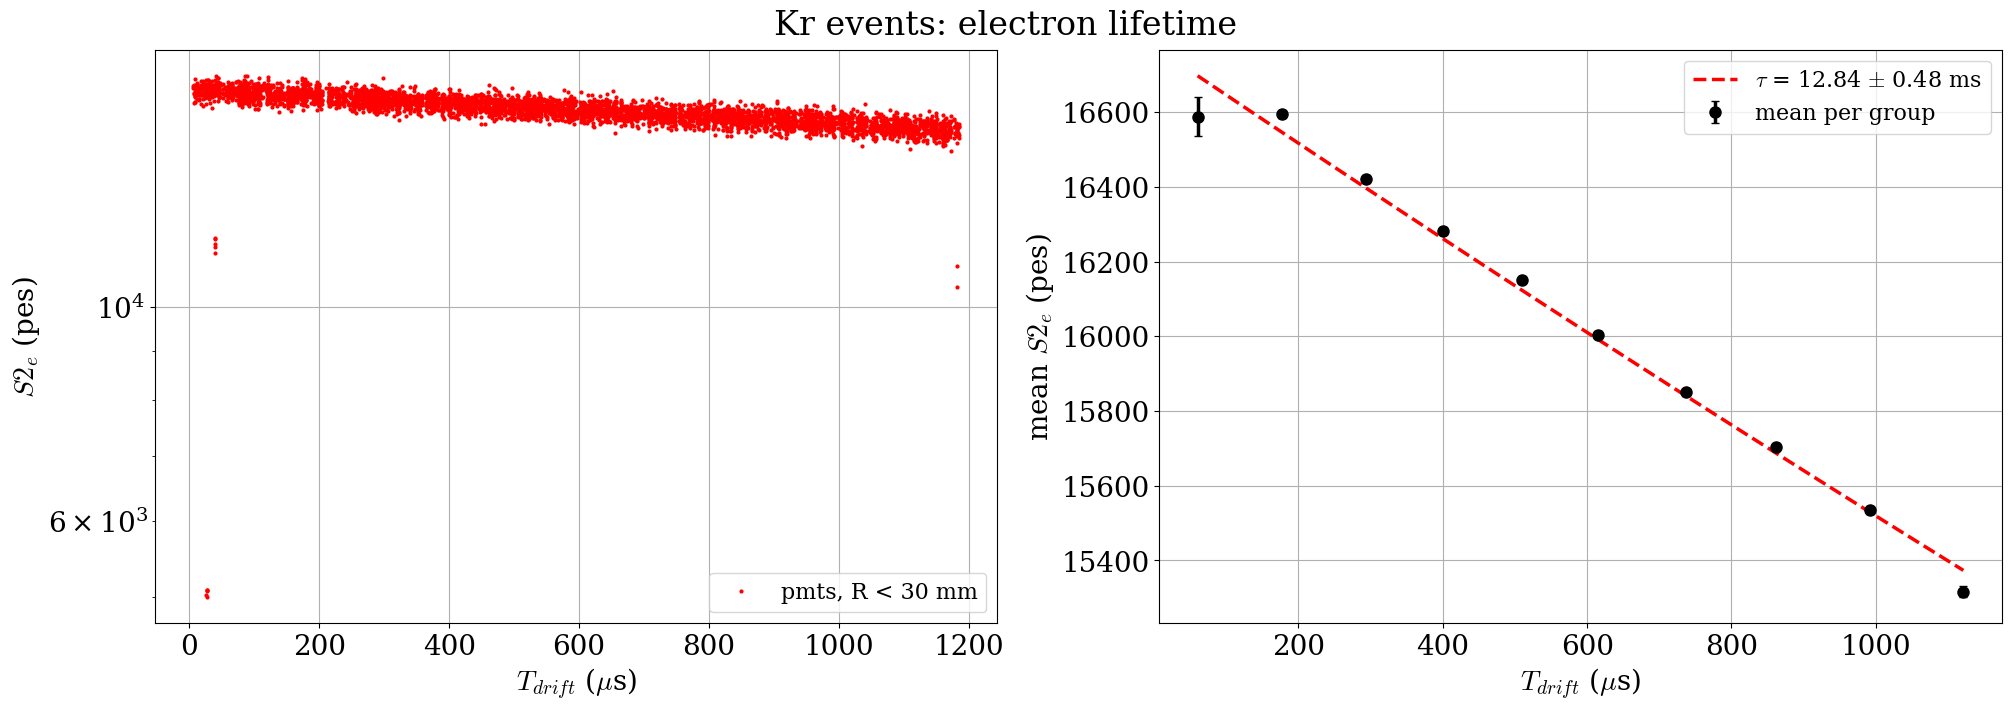

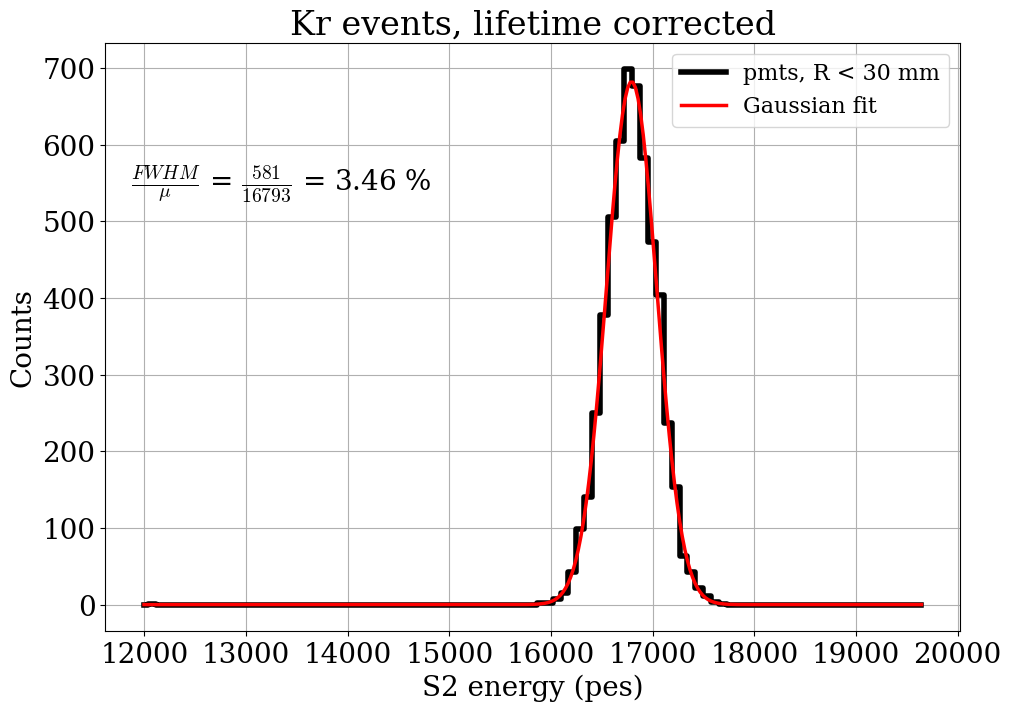

In [10]:
GS = GAIN / 365
tag = f"kr_{SAMPLE.split('_')[2]}_g{GAIN}"
show(plots.dst_compare(new["fibers"]["dst"], new["pmts"]["dst"], f"{SAMPLE}, gain {GAIN}: fibers vs PMTs", gain_scale=GS), f"{tag}_fib_vs_pmt")
for det in ["fibers", "pmts"]:
    r = new[det]; d = r["d"]
    show(plots.lifetime(d.Z.values / V_DRIFT, d.S2e.values, r["lt"], f"{det}, R < {RCUT} mm"), f"{tag}_{det}_lifetime")
    show(plots.peak_fit(r["cor"], f"{det}, R < {RCUT} mm", "Kr events, lifetime corrected"), f"{tag}_{det}_peak_corrected")